# A tour of Galileo
Galileo is a computer algebra system: it works with symbols as well as numbers. Each line of a cell is one statement; every result is shown.

## Numbers, variables and simplification

In [1]:
5/4
eval(5/4)
x + 7
x = 3
x + 7
clear

5/4

1.25

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

x+7

3
10

In [2]:
simplify(sin(y)^2 + cos(y)^2)
expand((a+b)^2)

1

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

a^2+2*a*b+b^2

> `expand`: Multiplies out products and powers.

## Calculus

In [3]:
f = x^3 - 2*x
deriv(f, x)

x^3-2*x

3*x^2-2

> `deriv`: Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

Integrals, limits and Taylor series. `integrate(f, x)` finds an antiderivative (without the constant), `integrate(f, x, a, b)` a definite integral; the limits can be `inf`:

In [4]:
integrate(x^2*sin(x), x)
integrate(1/(1+x^2), x, -inf, inf)
integrate(exp(-x^2), x, -inf, inf)

2*(x*sin(x)+cos(x))-x^2*cos(x)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

pi

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

sqrt(pi)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

The bell curve $e^{-x^2}$ has no antiderivative among the usual functions, yet its integral over the whole line comes out exact, $\sqrt\pi$; definite integrals with no formula at all are computed numerically. `limit(f, x, a)` and `taylor(f, x, a, n)`:

In [5]:
limit(sin(x)/x, x, 0)
limit((1 + 1/n)^n, n, inf)
taylor(cos(x), x, 0, 6)
sum(1/k^2, k, 1, 10)

1

> `limit`: Limit of f as x approaches a, from both sides or one side.

e

> `limit`: Limit of f as x approaches a, from both sides or one side.

-x^6/720+x^4/24-x^2/2+1

> `taylor`: Taylor polynomial of f around x = a (default 0) up to the term (x-a)^n.

1968329/1270080

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

## Solving equations

`solve(f, x)` solves $f = 0$ and returns every solution. Polynomials are solved exactly where possible, numerically otherwise; with a list of equations and unknowns it solves a linear system. `fsolve` finds a numeric root of any equation near a guess, and `factor` factors polynomials:

In [6]:
solve(x^2 - 5*x + 6, x)
solve(a*x^2 + b*x + c, x)
solve([x + y - 3, x - y - 1], [x y])
fsolve(cos(x) - x, x, 1)
factor(x^3 - 6*x^2 + 11*x - 6)

[2, 3]

> **Quadratic formula** x = (−b ± sqrt(D))/(2a) with D = b^2 − 4ac = `1`; D > 0: two real roots, rational because D is a perfect square.

[(-b-sqrt(b^2-4*a*c))/(2*a), (sqrt(b^2-4*a*c)-b)/(2*a)]

> **Quadratic formula** x = (−b ± sqrt(D))/(2a) with D = b^2 − 4ac = `b^2-4*a*c`; with letters its sign decides which case it is.

[2, 1]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

0.7390851332151607

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method); for a system, Newton's method with the Jacobian.

(x-3)*(x-2)*(x-1)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

## Plotting
`plot(f1, f2, ..., x, from, to)` samples expressions over a range; the range defaults to -10 .. 10. Variables you defined are substituted.

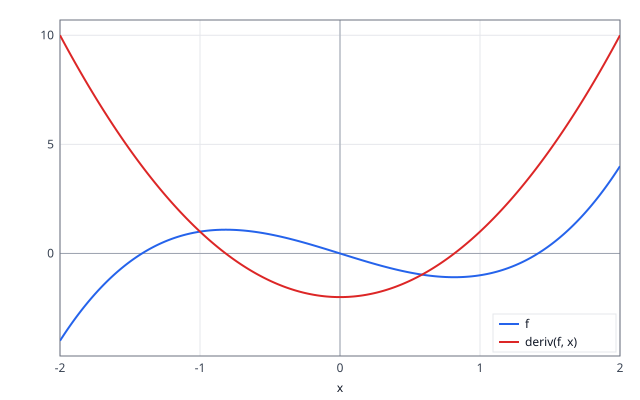

> `plot`: Plots one or more expressions of x.

In [7]:
plot(f, deriv(f, x), x, -2, 2)

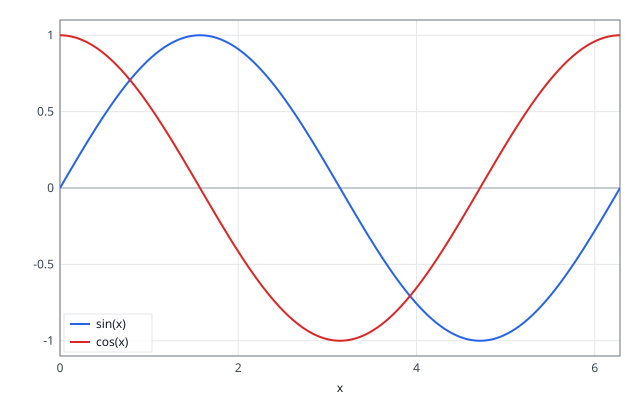

> `plot`: Plots one or more expressions of x.

In [8]:
plot(sin(x), cos(x), x, 0, 2*pi)

Poles are clipped instead of stretching the chart:

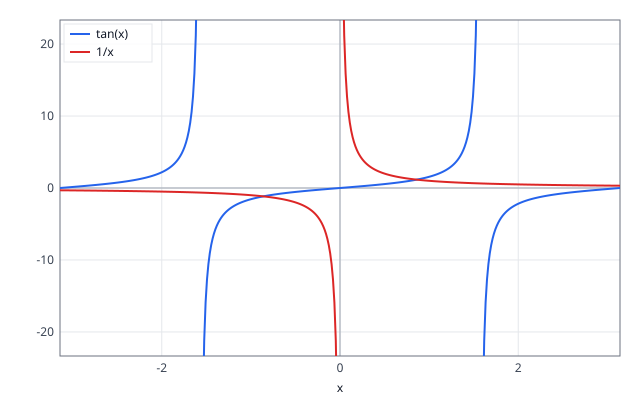

> `plot`: Plots one or more expressions of x.

In [9]:
plot(tan(x), 1/x, x, -pi, pi)

`parametric(fx, fy, t, from, to)` draws a curve given by two expressions of one parameter:

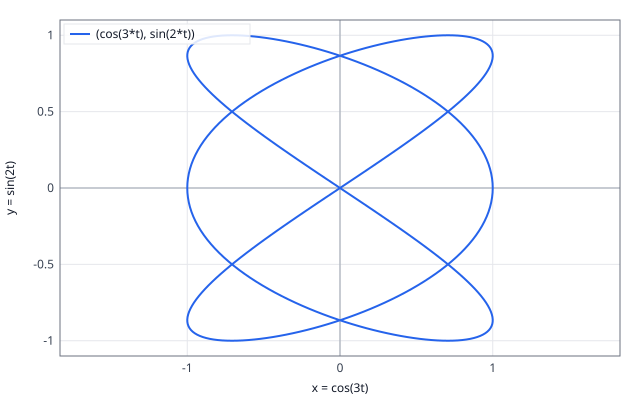

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
labels(parametric(cos(3*t), sin(2*t), t, 0, 2*pi), "x = cos(3t)", "y = sin(2t)")

Plots are values: assign them and overlay them with `show`:

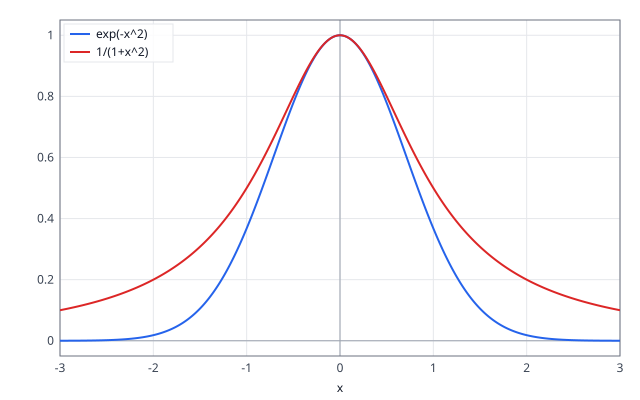

> `show`: Overlays plots: all 2D, or all 3D.

In [11]:
show(plot(exp(-x^2), x, -3, 3), plot(1/(1+x^2), x, -3, 3))

Give a plot a title, axis labels and legend names with `title`, `labels` (or `xlabel`, `ylabel`) and `legend`. They return a labelled copy, so they wrap around any plot:

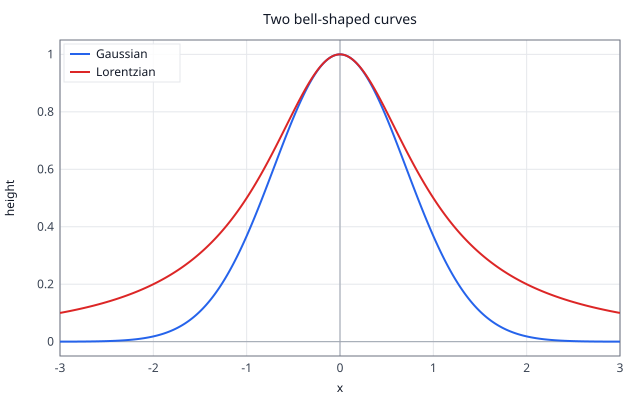

> `title`: A copy of plot p with a title or axis labels.

In [12]:
p = show(plot(exp(-x^2), x, -3, 3), plot(1/(1+x^2), x, -3, 3));
title(labels(legend(p, "Gaussian", "Lorentzian"), "x", "height"), "Two bell-shaped curves")

`polarplot(r, phi, from, to)` draws a curve given by its distance from the origin in each direction, here a cardioid:

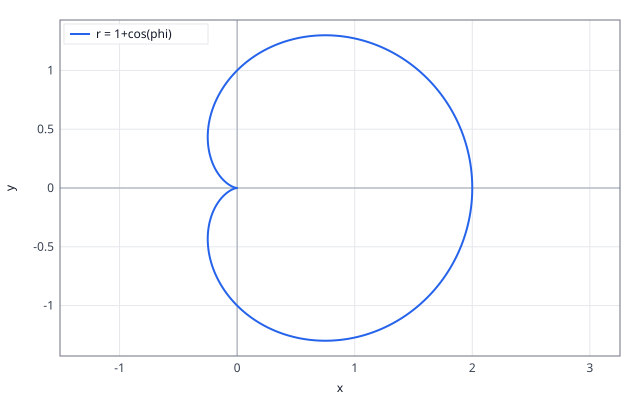

> `polarplot`: Plots the curve at distance r(phi) from the origin, for angles phi from..to.

In [13]:
polarplot(1 + cos(phi), phi, 0, 2*pi)

## 3D plots
In JupyterLab these are interactive: drag to rotate, scroll to zoom. `plot3d(f, x, a, b, y, c, d)` draws the surface z = f(x, y):

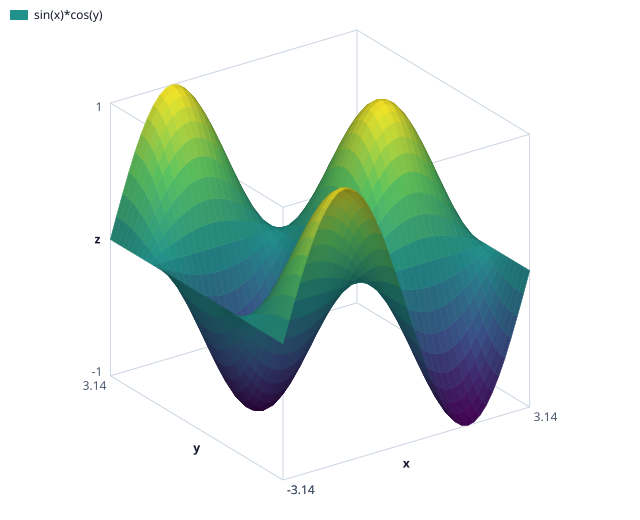

> `plot3d`: Plots the surface z = f(x, y) over a <= x <= b, c <= y <= d.

In [14]:
plot3d(sin(x)*cos(y), x, -pi, pi, y, -pi, pi)

`surface(fx, fy, fz, u, a, b, v, c, d)` draws a parametric surface, and `parametric3d(fx, fy, fz, t, a, b)` a curve in space. Here a (2,3) torus knot wound around its torus:

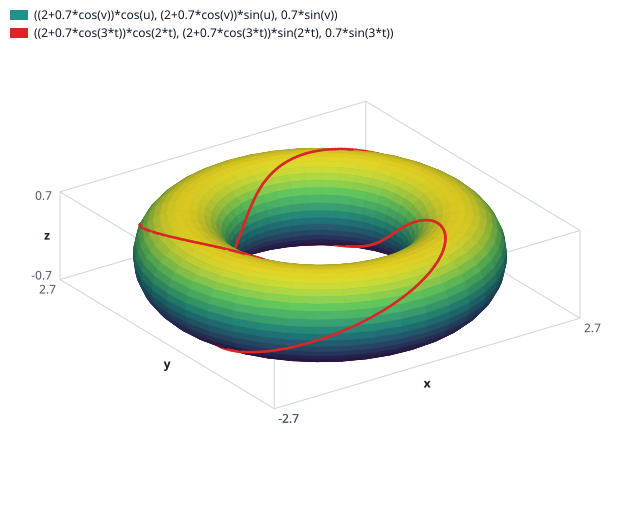

> `show`: Overlays plots: all 2D, or all 3D.

In [15]:
show(surface((2+0.7*cos(v))*cos(u), (2+0.7*cos(v))*sin(u), 0.7*sin(v), u, 0, 2*pi, v, 0, 2*pi), parametric3d((2+0.7*cos(3*t))*cos(2*t), (2+0.7*cos(3*t))*sin(2*t), 0.7*sin(3*t), t, 0, 2*pi))

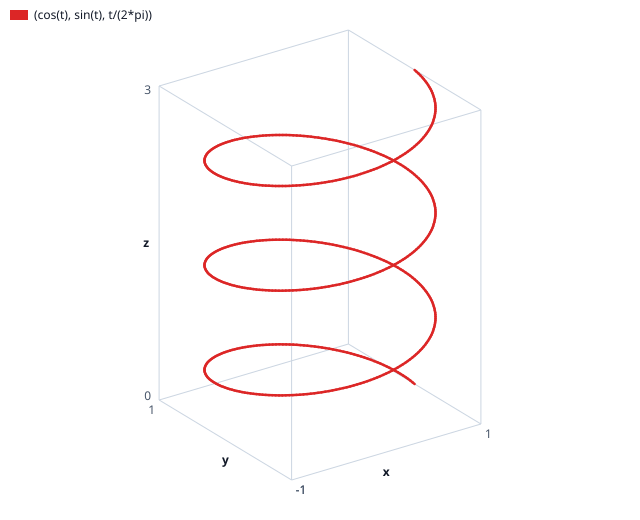

> `parametric3d`: Plots a curve in space.

In [16]:
parametric3d(cos(t), sin(t), t/(2*pi), t, 0, 6*pi)

## Matrices

In [17]:
A = [a b; c d]
inv(A)
A = [3 4; 5 b]
inv(A)

[a, b;
 c, d]

[d/(a*d-b*c), b/(b*c-a*d);
 c/(b*c-a*d), a/(a*d-b*c)]

> `inv`: Inverse of a matrix; works with symbolic entries.

[3, 4;
 5, b]

[b/(3*b-20), 4/(20-3*b);
 5/(20-3*b), 3/(3*b-20)]

> `inv`: Inverse of a matrix; works with symbolic entries.

Eigenvalues, the characteristic polynomial, traces and vector products:

In [18]:
eig([2 1; 1 2])
charpoly([2 1; 1 2], x)
trace([2 1; 1 2])
cross([1 0 0], [0 1 0])

[1, 3]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

x^2-4*x+3

> `charpoly` (see `eig`): Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

4

> `trace`: Sum of the diagonal entries; size gives [rows columns].

[0, 0, 1]

> `cross` (see `dot`): Dot product of two vectors, and cross product of two vectors of length 3.

## Tensors and general relativity
Galileo can compute Christoffel symbols, Ricci and Riemann tensors from a metric. See the [language reference](https://github.com/cascala/galileo/blob/master/docs/language.md) for more.